# Preparing the dataset for hippocampus segmentation

In this notebook you will use the skills and methods that we have talked about during our EDA Lesson to prepare the hippocampus dataset using Python. Follow the Notebook, writing snippets of code where directed so using Task comments, similar to the one below, which expects you to put the proper imports in place. Write your code directly in the cell with TASK comment. Feel free to add cells as you see fit, but please make sure that code that performs that tasked activity sits in the same cell as the Task comment.


In [1]:
# TASK: Import the following libraries that we will use: nibabel, matplotlib, numpy

import os
import csv
import glob
import shutil
import hashlib

import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams["figure.figsize"] = (10, 10)

It will help your understanding of the data a lot if you were able to use a tool that allows you to view NIFTI volumes, like [3D Slicer](https://www.slicer.org/). I will refer to Slicer throughout this Notebook and will be pasting some images showing what your output might look like.

## Loading NIFTI images using NiBabel

NiBabel is a python library for working with neuro-imaging formats (including NIFTI) that we have used in some of the exercises throughout the course. Our volumes and labels are in NIFTI format, so we will use nibabel to load and inspect them.

NiBabel documentation could be found here: https://nipy.org/nibabel/

Our dataset sits in two directories - *images* and *labels*. Each image is represented by a single file (we are fortunate to have our data converted to NIFTI) and has a corresponding label file which is named the same as the image file.

Note that our dataset is "dirty". There are a few images and labels that are not quite right. They should be quite obvious to notice, though. The dataset contains an equal amount of "correct" volumes and corresponding labels, and you don't need to alter values of any samples in order to get the clean dataset.

In [2]:
# TASK: Your data sits in directory /data/TrainingSet.
# Load an image and a segmentation mask into variables called image and label

# The Udacity workspace mounts the data at /data/TrainingSet. Outside it, set HIPPO_DATA
# or use the copy of the starter repository's data folder kept next to the section folders.
DATA_DIR = os.environ.get("HIPPO_DATA") or (
    "/data/TrainingSet" if os.path.isdir("/data/TrainingSet") else
    next(p for p in ("../data/TrainingSet", "../../data/TrainingSet") if os.path.isdir(p)))
OUT_DIR = "../data/curated"
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)

list_nii = lambda d: sorted(f for f in os.listdir(os.path.join(DATA_DIR, d))
                            if f.endswith((".nii", ".nii.gz")) and not f.startswith("."))
image_files, label_files = list_nii("images"), list_nii("labels")
print("Data directory:", DATA_DIR)
print(f"{len(image_files)} image files, {len(label_files)} label files")
print("Images without a label:", sorted(set(image_files) - set(label_files)))
print("Labels without an image:", sorted(set(label_files) - set(image_files)))
print("Non-NIfTI / hidden entries:", sorted(
    f for d in ("images", "labels") for f in os.listdir(os.path.join(DATA_DIR, d))
    if f not in image_files + label_files))

SAMPLE = "hippocampus_001.nii.gz"
image = nib.load(os.path.join(DATA_DIR, "images", SAMPLE))
label = nib.load(os.path.join(DATA_DIR, "labels", SAMPLE))

Data directory: ../data/TrainingSet
263 image files, 262 label files
Images without a label: ['hippocampus_118.nii.gz']
Labels without an image: []
Non-NIfTI / hidden entries: ['.DS_Store']


Image shape: (35, 51, 35) | label shape: (35, 51, 35)
Label values: [0 1 2] | affine matches: True


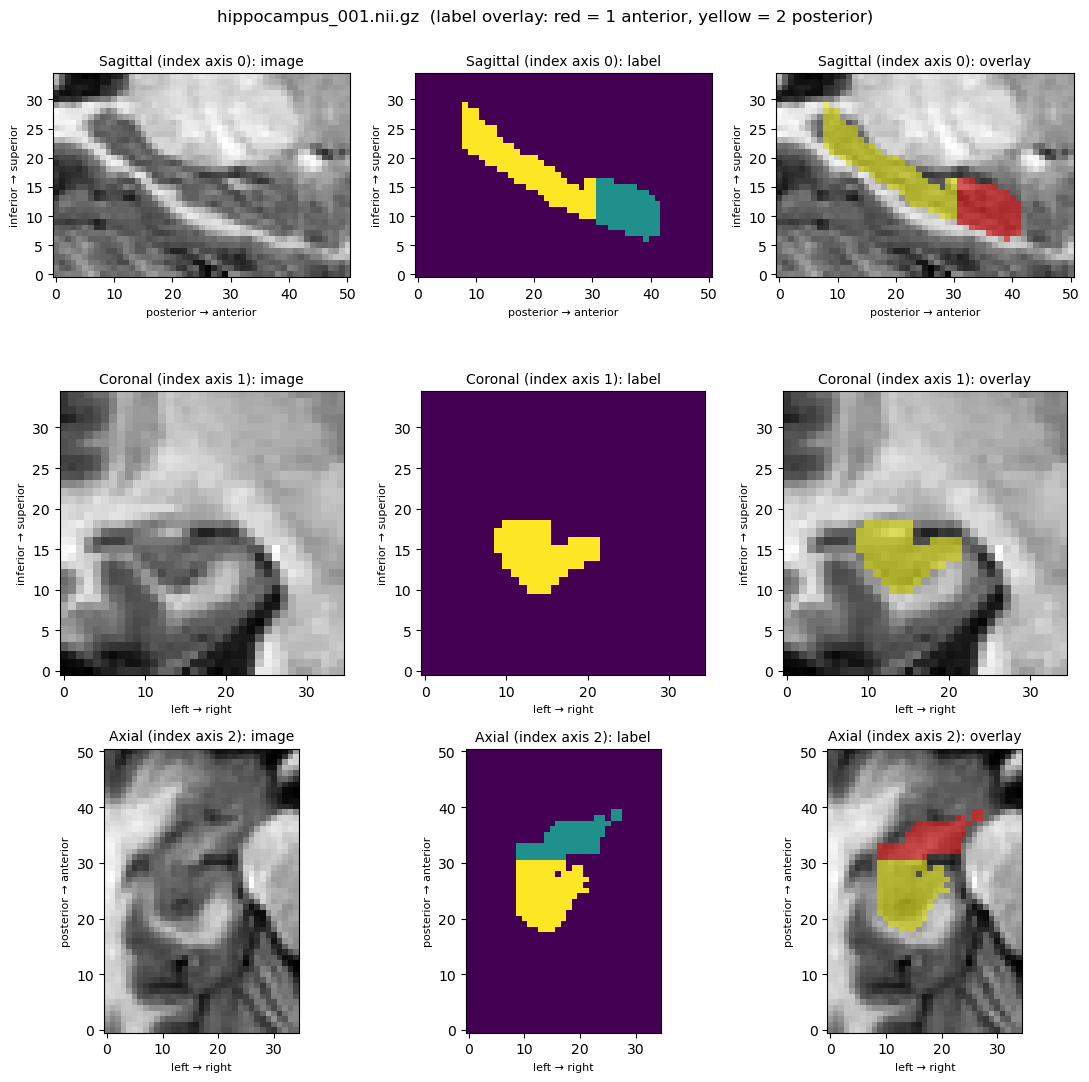

In [3]:
# Nibabel can present your image data as a Numpy array by calling the method get_fdata()
# The array will contain a multi-dimensional Numpy array with numerical values representing voxel intensities. 
# In our case, images and labels are 3-dimensional, so get_fdata will return a 3-dimensional array. You can verify this
# by accessing the .shape attribute. What are the dimensions of the input arrays?

# TASK: using matplotlib, visualize a few slices from the dataset, along with their labels. 
# You can adjust plot sizes like so if you find them too small:
# plt.rcParams["figure.figsize"] = (10,10)

img = image.get_fdata()
lbl = np.asanyarray(label.dataobj).astype(np.uint8)
print("Image shape:", img.shape, "| label shape:", lbl.shape)
print("Label values:", np.unique(lbl), "| affine matches:", np.allclose(image.affine, label.affine))

def planes(vol, mask):
    """Centre slice through the mask in each plane, for a RAS volume."""
    c = np.round(np.argwhere(mask > 0).mean(0)).astype(int)
    return [("Sagittal (index axis 0)", vol[c[0], :, :], mask[c[0], :, :], ("posterior → anterior", "inferior → superior")),
            ("Coronal (index axis 1)", vol[:, c[1], :], mask[:, c[1], :], ("left → right", "inferior → superior")),
            ("Axial (index axis 2)", vol[:, :, c[2]], mask[:, :, c[2]], ("left → right", "posterior → anterior"))]

def show_sample(vol, mask, title, path=None):
    fig, ax = plt.subplots(3, 3, figsize=(11, 11))
    for row, (name, i2d, m2d, (xl, yl)) in enumerate(planes(vol, mask)):
        for col, what in enumerate(("image", "label", "overlay")):
            a = ax[row, col]
            if what != "label":
                a.imshow(i2d.T, cmap="gray", origin="lower")
            if what == "label":
                a.imshow(m2d.T, cmap="viridis", origin="lower", vmin=0, vmax=2, interpolation="nearest")
            if what == "overlay":
                a.imshow(np.ma.masked_equal(m2d, 0).T, cmap="autumn", origin="lower", vmin=1, vmax=2,
                         alpha=0.5, interpolation="nearest")
            a.set_title(f"{name}: {what}", fontsize=10)
            a.set_xlabel(xl, fontsize=8)
            a.set_ylabel(yl, fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    if path:
        fig.savefig(path, dpi=90)
    plt.show()

show_sample(img, lbl, f"{SAMPLE}  (label overlay: red = 1 anterior, yellow = 2 posterior)",
            os.path.join(FIG_DIR, "sample_three_planes.png"))

*Figure: one slice per anatomical plane through the centre of the mask. The answer to “what are the dimensions?” is printed above: each sample is a small 3D crop (tens of voxels per side), and crop sizes differ between samples. The overlay lets us check by eye that image and mask are aligned.*

3D Slicer was not used in this run; alignment was checked with these overlays and with the shape and affine comparisons.

Load volume into 3D Slicer to validate that your visualization is correct and get a feel for the shape of structures.Try to get a visualization like the one below (hint: while Slicer documentation is not particularly great, there are plenty of YouTube videos available! Just look it up on YouTube if you are not sure how to do something)

*(course illustration omitted)*

In [4]:
# Stand out suggestion: use one of the simple Volume Rendering algorithms that we've
# implemented in one of our earlier lessons to visualize some of these volumes

## Looking at single image data
In this section we will look closer at the NIFTI representation of our volumes. In order to measure the physical volume of hippocampi, we need to understand the relationship between the sizes of our voxels and the physical world.

In [5]:
# Nibabel supports many imaging formats, NIFTI being just one of them. I told you that our images 
# are in NIFTI, but you should confirm if this is indeed the format that we are dealing with
# TASK: using .header_class attribute - what is the format of our images?

print("header_class:", image.header_class)
print("object type :", type(image).__name__)
print("magic       :", image.header["magic"], "(n+1 = single-file NIfTI-1)")
print("sizeof_hdr  :", image.header["sizeof_hdr"], "(348 bytes = NIfTI-1)")
# ANSWER: the files are NIfTI-1 (nibabel header class Nifti1Header).

header_class: <class 'nibabel.nifti1.Nifti1Header'>
object type : Nifti1Image
magic       : b'n+1' (n+1 = single-file NIfTI-1)
sizeof_hdr  : 348 (348 bytes = NIfTI-1)


Further down we will be inspecting .header attribute that provides access to NIFTI metadata. You can use this resource as a reference for various fields: https://brainder.org/2012/09/23/the-nifti-file-format/

In [6]:
# TASK: How many bits per pixel are used?

for name, n in (("image", image), ("label", label)):
    print(f"{name}: bitpix={int(n.header['bitpix'])}, dtype={n.header.get_data_dtype()}")
# ANSWER: for this sample the numbers are printed above. Storage type differs between files;
# the table in the outlier section counts bits per pixel over the whole dataset.

image: bitpix=8, dtype=uint8
label: bitpix=8, dtype=uint8


In [7]:
# TASK: What are the units of measurement?

xyz, t = image.header.get_xyzt_units()
print("xyzt_units code:", int(image.header["xyzt_units"]), "-> spatial:", xyz, "| temporal:", t)
# ANSWER: spatial unit is the millimetre (the temporal unit is irrelevant for a static 3D scan).

xyzt_units code: 10 -> spatial: mm | temporal: sec


In [8]:
# TASK: Do we have a regular grid? What are grid spacings?

zooms = image.header.get_zooms()
R = image.affine[:3, :3]
cos = (R / np.linalg.norm(R, axis=0)).T @ (R / np.linalg.norm(R, axis=0))
print("pixdim / zooms (mm):", zooms)
print("affine:\n", image.affine)
print("axes mutually orthogonal:", np.allclose(cos, np.eye(3)))
# ANSWER: yes, a regular rectilinear grid. Spacing is printed above (1 x 1 x 1 mm, isotropic).

pixdim / zooms (mm): (1.0, 1.0, 1.0)
affine:
 [[1. 0. 0. 1.]
 [0. 1. 0. 1.]
 [0. 0. 1. 1.]
 [0. 0. 0. 1.]]
axes mutually orthogonal: True


In [9]:
# TASK: What dimensions represent axial, sagittal, and coronal slices? How do you know?

codes = nib.aff2axcodes(image.affine)
print("Direction in which each array axis increases:", codes)
for ax_i, code in enumerate(codes):
    plane = {"R": "sagittal", "L": "sagittal", "A": "coronal", "P": "coronal", "S": "axial", "I": "axial"}[code]
    print(f"  array axis {ax_i} points to {code}: fixing its index gives a {plane} slice")

# Cross-check the label convention: class 1 should lie anterior (larger A coordinate) to class 2
cen = {k: nib.affines.apply_affine(label.affine, np.argwhere(lbl == k).mean(0)) for k in (1, 2)}
print("Centroid of class 1 (RAS mm):", cen[1].round(1))
print("Centroid of class 2 (RAS mm):", cen[2].round(1))
# ANSWER: the affine maps array indices to RAS world coordinates, so axis 0 = left-right
# (sagittal slices), axis 1 = posterior-anterior (coronal slices), axis 2 = inferior-superior
# (axial slices). We read this from the affine; we do not assume it from the array order.

Direction in which each array axis increases: ('R', 'A', 'S')
  array axis 0 points to R: fixing its index gives a sagittal slice
  array axis 1 points to A: fixing its index gives a coronal slice
  array axis 2 points to S: fixing its index gives a axial slice
Centroid of class 1 (RAS mm): [18.9 37.6 12. ]
Centroid of class 2 (RAS mm): [15.4 20.2 19.4]


In [10]:
# By now you should have enough information to decide what are dimensions of a single voxel
# TASK: Compute the volume (in mm³) of a hippocampus using one of the labels you've loaded. 
# You should get a number between ~2200 and ~4500

def voxel_volume_mm3(nii):
    """|det| of the 3x3 spatial part of the affine; valid for oblique and sheared grids too."""
    return float(abs(np.linalg.det(nii.affine[:3, :3])))

def hippocampus_volumes(nii):
    """Physical volumes in mm^3. Label values are class ids, so we COUNT voxels, never sum them."""
    m = np.asanyarray(nii.dataobj)
    v = voxel_volume_mm3(nii)
    ant, post = int((m == 1).sum()) * v, int((m == 2).sum()) * v
    return {"anterior": ant, "posterior": post, "total": ant + post}

print("voxel volume from affine:", voxel_volume_mm3(label), "mm^3;",
      "from zooms:", float(np.prod(label.header.get_zooms()[:3])))
print(SAMPLE, hippocampus_volumes(label))
print("(summing label values instead would wrongly give", int(lbl.sum()), ")")

voxel volume from affine: 1.0 mm^3; from zooms: 1.0
hippocampus_001.nii.gz {'anterior': 1324.0, 'posterior': 1624.0, 'total': 2948.0}
(summing label values instead would wrongly give 4572 )


## Plotting some charts

image_dtype [('float32', 207), ('uint8', 56)]
image_bitpix [('32', 207), ('8', 56)]
image_zooms [('(1.0, 1.0, 1.0)', 261), ('(0.598, 0.598, 1.25)', 1), ('(0.785, 0.785, 7.5)', 1)]
image_axcodes [('RAS', 262), ('LAS', 1)]
label_dtype [('uint8', 260), ('float32', 2)]
label_zooms [('(1.0, 1.0, 1.0)', 261), ('(0.734, 0.734, 5.0)', 1)]


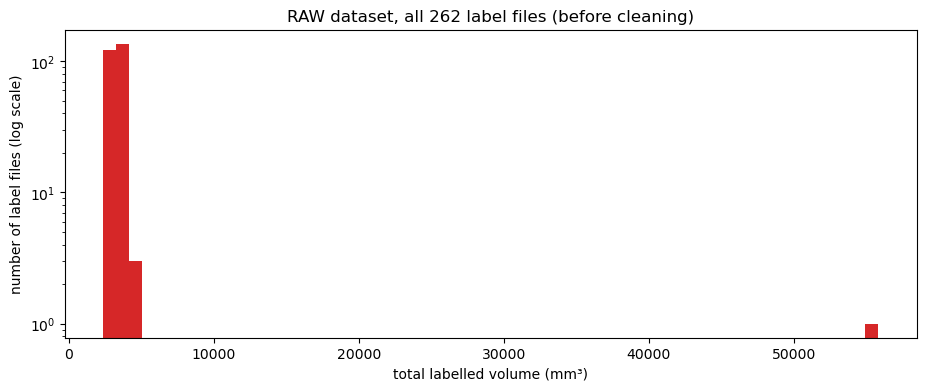

hippocampus_279.nii.gz: total 2382 mm³
hippocampus_143.nii.gz: total 2397 mm³
hippocampus_282.nii.gz: total 2416 mm³
hippocampus_319.nii.gz: total 2422 mm³
hippocampus_006.nii.gz: total 4263 mm³
hippocampus_242.nii.gz: total 4383 mm³
hippocampus_368.nii.gz: total 4401 mm³
hippocampus_281.nii.gz: total 55824 mm³


In [11]:
# TASK: Plot a histogram of all volumes that we have in our dataset and see how 
# our dataset measures against a slice of a normal population represented by the chart below.

records = []
for f in sorted(set(image_files) | set(label_files)):
    r = {"filename": f, "has_image": f in image_files, "has_label": f in label_files}
    for kind, key in (("images", "image"), ("labels", "label")):
        p = os.path.join(DATA_DIR, kind, f)
        if not os.path.exists(p):
            continue
        try:
            n = nib.load(p)
            data = np.asanyarray(n.dataobj)
        except Exception as e:                       # corrupted / unreadable file
            r[f"{key}_error"] = str(e)
            continue
        r[f"{key}_shape"] = data.shape
        r[f"{key}_zooms"] = tuple(round(float(z), 3) for z in n.header.get_zooms()[:3])
        r[f"{key}_bitpix"] = int(n.header["bitpix"])
        r[f"{key}_dtype"] = str(n.header.get_data_dtype())
        r[f"{key}_axcodes"] = "".join(nib.aff2axcodes(n.affine))
        r[f"{key}_bytes"] = os.path.getsize(p)
        r[f"{key}_min"], r[f"{key}_max"] = float(data.min()), float(data.max())
        r[f"_{key}_affine"] = n.affine
        if key == "image":
            r["image_sha1"] = hashlib.sha1(np.ascontiguousarray(data).tobytes()).hexdigest()
        else:
            r["label_values"] = np.unique(data).tolist()[:10]
            r.update({f"vol_{k}": v for k, v in hippocampus_volumes(n).items()})
    records.append(r)

import collections
for key in ("image_dtype", "image_bitpix", "image_zooms", "image_axcodes", "label_dtype", "label_zooms"):
    print(key, collections.Counter(str(r[key]) for r in records if key in r).most_common())

with_label = [r for r in records if "vol_total" in r]
totals = np.array([r["vol_total"] for r in with_label])

plt.figure(figsize=(11, 4))
plt.hist(totals, bins=60, color="tab:red")
plt.yscale("log")
plt.xlabel("total labelled volume (mm³)")
plt.ylabel("number of label files (log scale)")
plt.title(f"RAW dataset, all {len(totals)} label files (before cleaning)")
plt.savefig(os.path.join(FIG_DIR, "hist_total_raw.png"), dpi=100, bbox_inches="tight")
plt.show()
for r in sorted(with_label, key=lambda r: r["vol_total"])[:4] + sorted(with_label, key=lambda r: r["vol_total"])[-4:]:
    print(f'{r["filename"]}: total {r["vol_total"]:.0f} mm³')

*(course illustration omitted)*

Do you see any outliers? Why do you think it's so (might be not immediately obvious, but it's always a good idea to inspect) outliers closer. If you haven't found the images that do not belong, the histogram may help you.

In [12]:
# Rule-based screening. A sample is EXCLUDED only for a structural defect, never merely for
# being far from the mean. Volume tails are inspected visually further below and kept if plausible.
def structural_problems(r):
    out = []
    if not r["has_image"]: out.append("label has no matching image")
    if not r["has_label"]: out.append("image has no matching segmentation mask")
    for k in ("image", "label"):
        if f"{k}_error" in r: out.append(f"{k} unreadable: {r[k + '_error']}")
    if "image_shape" in r and (len(r["image_shape"]) != 3 or max(r["image_shape"]) > 64):
        out.append(f"image is not a hippocampus crop: shape {r['image_shape']}, spacing {r['image_zooms']} mm, "
                   f"intensity range [{r['image_min']:.0f}, {r['image_max']:.0f}]")
    if "image_shape" in r and "label_shape" in r:
        if r["image_shape"] != r["label_shape"]:
            out.append(f"image shape {r['image_shape']} != label shape {r['label_shape']}")
        elif not np.allclose(r["_image_affine"], r["_label_affine"], atol=1e-3):
            out.append("image and label affines differ (misaligned)")
    if "label_values" in r:
        if not set(r["label_values"]) <= {0, 1, 2}: out.append(f"unexpected label values {r['label_values']}")
        elif r["vol_anterior"] == 0 or r["vol_posterior"] == 0: out.append("an anatomical region is missing")
    return out

excluded = {r["filename"]: structural_problems(r) for r in records}
excluded = {k: v for k, v in excluded.items() if v}
for f, why in excluded.items():
    print(f); [print("    -", w) for w in why]

shas = collections.Counter(r["image_sha1"] for r in records if "image_sha1" in r)
print("exact duplicate images:", sum(c - 1 for c in shas.values() if c > 1))

hippocampus_010.nii.gz
    - image is not a hippocampus crop: shape (512, 512, 241), spacing (0.598, 0.598, 1.25) mm, intensity range [-1024, 3071]
    - image shape (512, 512, 241) != label shape (36, 50, 31)
hippocampus_118.nii.gz
    - image has no matching segmentation mask
hippocampus_281.nii.gz
    - image is not a hippocampus crop: shape (512, 512, 31), spacing (0.785, 0.785, 7.5) mm, intensity range [-1024, 1166]
    - image shape (512, 512, 31) != label shape (512, 512, 94)
    - an anatomical region is missing
exact duplicate images: 0


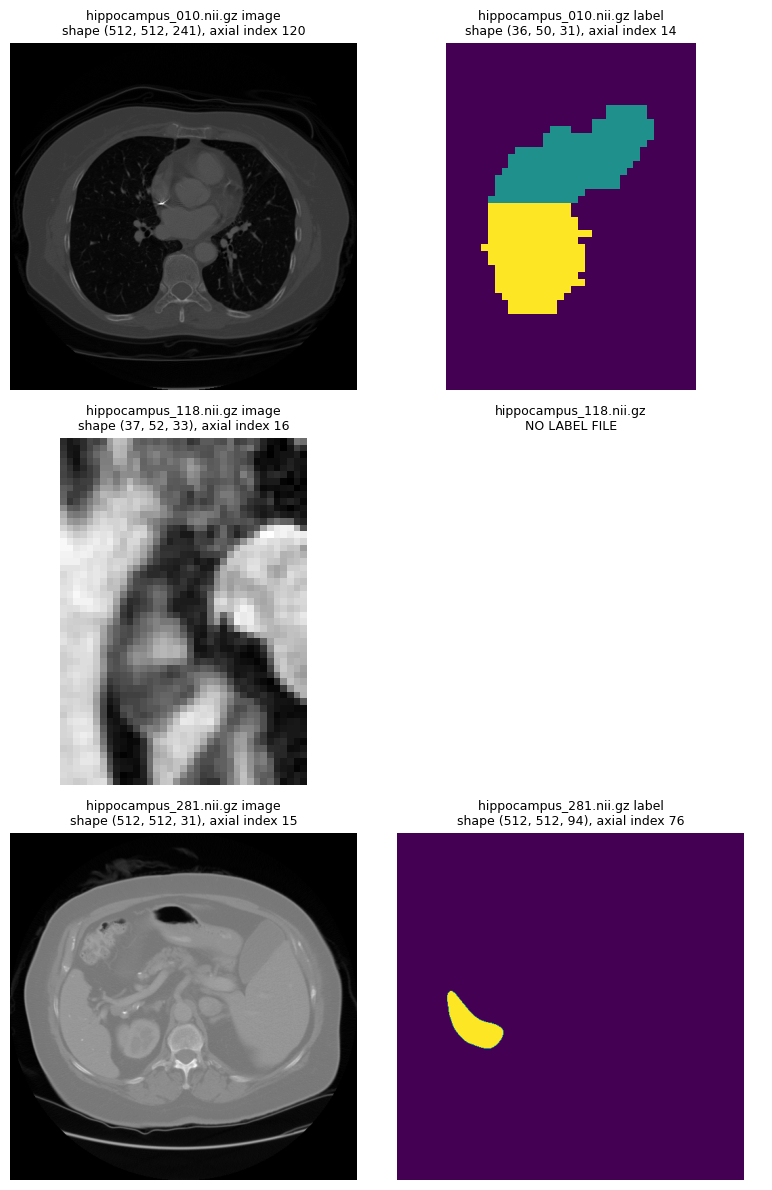

In [13]:
# Look at the excluded files (supporting observation for each exclusion)
by_name = {r["filename"]: r for r in records}
n = len(excluded)
fig, ax = plt.subplots(n, 2, figsize=(8, 4 * n), squeeze=False)
for row, f in enumerate(excluded):
    for col, kind in enumerate(("images", "labels")):
        a = ax[row, col]; a.axis("off")
        p = os.path.join(DATA_DIR, kind, f)
        if not os.path.exists(p):
            a.set_title(f"{f}\nNO {kind[:-1].upper()} FILE", fontsize=9); continue
        d = np.asanyarray(nib.load(p).dataobj)
        k = int(np.argmax((d > 0).sum((0, 1)))) if kind == "labels" else d.shape[2] // 2
        a.imshow(d[:, :, k].T, cmap="gray" if kind == "images" else "viridis", origin="lower")
        a.set_title(f"{f} {kind[:-1]}\nshape {d.shape}, axial index {k}", fontsize=9)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "excluded_samples.png"), dpi=80); plt.show()

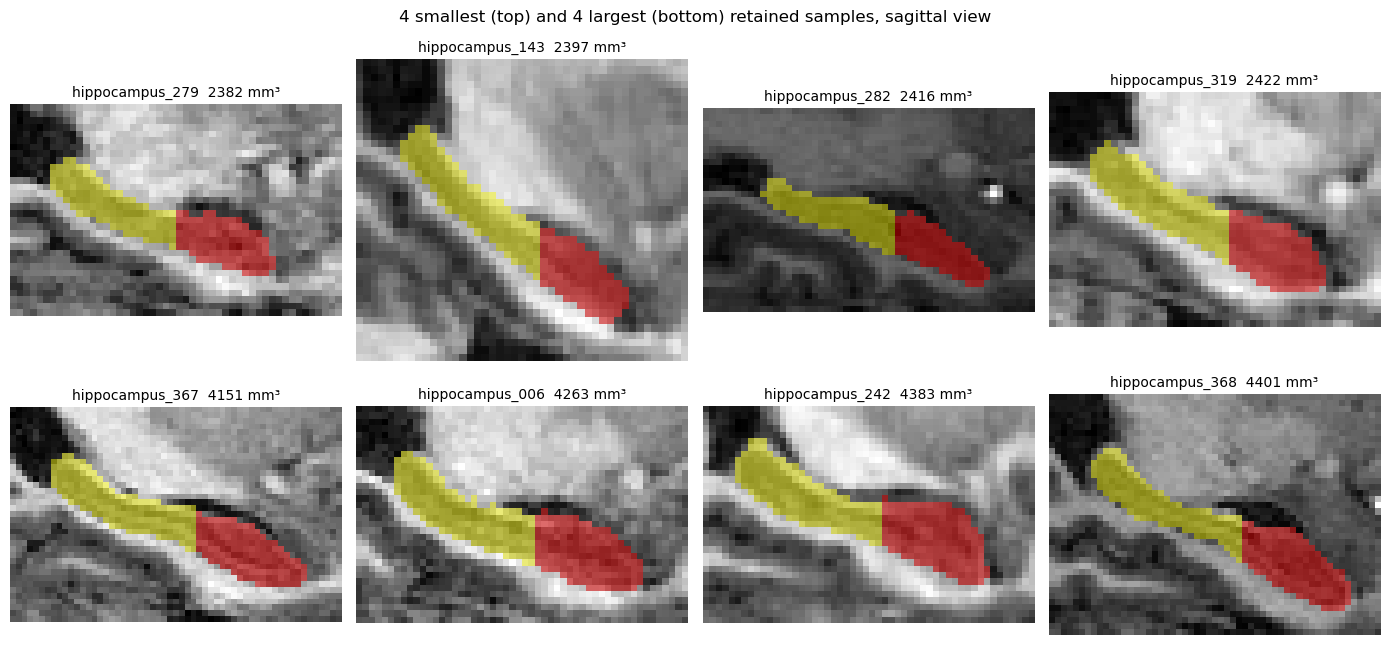

In [14]:
# Volume tails among structurally valid samples: inspect before deciding anything
clean = [r for r in records if r["filename"] not in excluded]
ordered = sorted(clean, key=lambda r: r["vol_total"])
tails = ordered[:4] + ordered[-4:]
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for a, r in zip(ax.ravel(), tails):
    d = nib.load(os.path.join(DATA_DIR, "images", r["filename"])).get_fdata()
    m = np.asanyarray(nib.load(os.path.join(DATA_DIR, "labels", r["filename"])).dataobj)
    i = int(np.argmax((m > 0).sum((1, 2))))
    a.imshow(d[i].T, cmap="gray", origin="lower")
    a.imshow(np.ma.masked_equal(m[i], 0).T, cmap="autumn", origin="lower", vmin=1, vmax=2, alpha=0.45)
    a.set_title(f'{r["filename"][:-7]}  {r["vol_total"]:.0f} mm³', fontsize=10); a.axis("off")
fig.suptitle("4 smallest (top) and 4 largest (bottom) retained samples, sagittal view")
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "volume_tails.png"), dpi=90); plt.show()

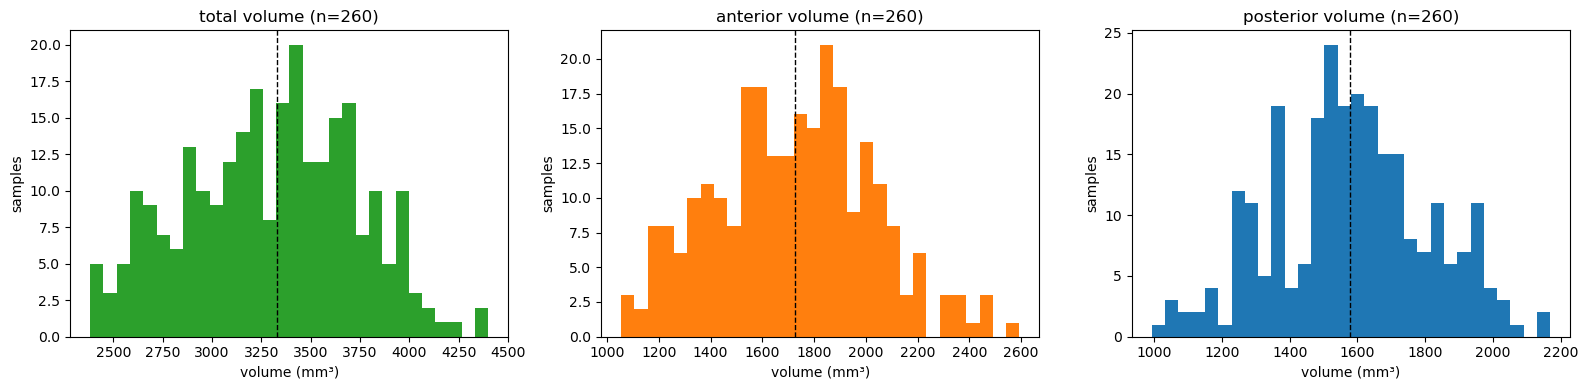

stat           total    anterior   posterior
n              260.0       260.0       260.0
min           2382.0      1054.0       993.0
q05           2587.1      1215.8      1229.7
q25           2949.5      1514.8      1434.5
median        3326.5      1725.0      1578.5
mean          3295.2      1715.1      1580.1
q75           3624.2      1908.8      1721.0
q95           3979.2      2221.0      1950.3
max           4401.0      2593.0      2169.0
std            433.4       307.2       228.8

Approx. nomogram 2.5th-97.5th percentile, ages 52-71: about 3000-4640 mm³ (read from chart)
  share of curated samples in [0, 3000): 26.5%
  share of curated samples in [3000, 4640): 73.5%
  share of curated samples in [4640, inf): 0.0%


In [15]:
# Distributions and summary statistics of the CURATED set
cols = ("total", "anterior", "posterior")
V = {k: np.array([r[f"vol_{k}"] for r in clean]) for k in cols}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, k, c in zip(ax, cols, ("tab:green", "tab:orange", "tab:blue")):
    a.hist(V[k], bins=30, color=c); a.set_title(f"{k} volume (n={len(V[k])})")
    a.set_xlabel("volume (mm³)"); a.set_ylabel("samples")
    a.axvline(np.median(V[k]), color="k", ls="--", lw=1)
fig.tight_layout(); fig.savefig(os.path.join(FIG_DIR, "hist_volumes_curated.png"), dpi=100); plt.show()

stat_fns = {"n": len, "min": np.min, "q05": lambda x: np.percentile(x, 5), "q25": lambda x: np.percentile(x, 25),
            "median": np.median, "mean": np.mean, "q75": lambda x: np.percentile(x, 75),
            "q95": lambda x: np.percentile(x, 95), "max": np.max, "std": lambda x: np.std(x, ddof=1)}
with open(os.path.join(OUT_DIR, "volume_statistics.csv"), "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["statistic_mm3", *cols])
    print(f"{'stat':8s}" + "".join(f"{c:>12s}" for c in cols))
    for s, fn in stat_fns.items():
        row = [round(float(fn(V[c])), 1) for c in cols]
        w.writerow([s, *row]); print(f"{s:8s}" + "".join(f"{x:12.1f}" for x in row))

# Right-hippocampus female nomogram (Nobis et al. 2019), values read by eye from the supplied chart
print("\nApprox. nomogram 2.5th-97.5th percentile, ages 52-71: about 3000-4640 mm³ (read from chart)")
for lo, hi in ((0, 3000), (3000, 4640), (4640, 1e9)):
    frac = np.mean((V["total"] >= lo) & (V["total"] < hi))
    print(f"  share of curated samples in [{lo}, {hi if hi < 1e9 else 'inf'}): {100 * frac:.1f}%")

## Conclusions from the exploratory analysis

**Data.** 263 image files and 262 label files were supplied. Three sample ids are excluded, each for a structural defect (not for being statistically unusual); 260 matched image/label pairs remain.

| id | reason | observation |
|---|---|---|
| hippocampus_010 | image is not a hippocampus crop | 512×512×241, intensities from −1024 (CT-like), shows a chest; its label is a small crop of a different shape |
| hippocampus_118 | no segmentation mask | image only |
| hippocampus_281 | wrong anatomy and modality | 512×512×31 CT-like abdomen; label is 512×512×94 with a single class, shaped unlike a hippocampus |

**Metadata (retained set).** NIfTI-1, 1 × 1 × 1 mm orthogonal grid, millimetre units, RAS orientation. Bits per pixel differ: 205 images are 32-bit float and 55 are 8-bit unsigned; two retained label files (003, 243) are stored as float32 but contain only 0/1/2. Intensity scales differ by orders of magnitude between files (float volumes reach maxima from about 850 to 1.7 million), so MRI intensities are not comparable across volumes and each volume must be normalised individually.

**Volumes.** Total labelled volume is 2382–4401 mm³ (median 3326, mean 3295, SD 433). Anterior (class 1) is on average slightly larger than posterior (class 2). The smallest and largest cases look anatomically coherent with well-aligned masks, so they are retained.

**Comparison with the nomogram.** The supplied chart is for the *right* hippocampus of women aged 52–71, corrected for head size, and its 2.5th–97.5th percentile band is roughly 3000–4640 mm³. About 26% of our samples fall below it and none above. This does **not** show that those samples are atrophic: we have no age, sex, side or head size for them, and the labelling protocol and scanner differ from UK Biobank. It is a reason not to apply that nomogram to this model's output without a matched validation.

**Limits of this analysis.** Visual review covered the displayed examples, not all 260 masks. The files carry no subject identifiers, so we cannot tell whether two samples come from the same person (for example, two hemispheres). Neither the label quality nor the hemisphere of each crop could be verified from the files alone.


In the real world we would have precise information about the ages and conditions of our patients, and understanding how our dataset measures against population norm would be the integral part of clinical validation that we talked about in last lesson. Unfortunately, we do not have this information about this dataset, so we can only guess why it measures the way it is. If you would like to explore further, you can use the [calculator from HippoFit project](http://www.smanohar.com/biobank/calculator.html) to see how our dataset compares against different population slices

Did you notice anything odd about the label files? We hope you did! The mask seems to have two classes, labeled with values `1` and `2` respectively. If you visualized sagittal or axial views, you might have gotten a good guess of what those are. Class 1 is the anterior segment of the hippocampus and class 2 is the posterior one. 

For the purpose of volume calculation we do not care about the distinction, however we will still train our network to differentiate between these two classes and the background

In [16]:
# TASK: Copy the clean dataset to the output folder inside section1/out. You will use it in the next Section

for sub in ("images", "labels"):
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)
    for old in glob.glob(os.path.join(OUT_DIR, sub, "*.nii.gz")):
        os.remove(old)                      # keep reruns from leaving stale files behind

for r in clean:                             # byte-for-byte copies keep headers and affines intact
    for sub in ("images", "labels"):
        shutil.copy2(os.path.join(DATA_DIR, sub, r["filename"]), os.path.join(OUT_DIR, sub, r["filename"]))

fields = ["filename", "status", "image_shape", "image_zooms", "image_dtype", "vol_anterior", "vol_posterior", "vol_total"]
with open(os.path.join(OUT_DIR, "dataset_manifest.csv"), "w", newline="") as fh:
    w = csv.DictWriter(fh, fieldnames=fields, extrasaction="ignore"); w.writeheader()
    for r in records:
        w.writerow({**r, "status": "excluded" if r["filename"] in excluded else "included"})
with open(os.path.join(OUT_DIR, "exclusion_log.csv"), "w", newline="") as fh:
    w = csv.writer(fh); w.writerow(["filename", "reasons", "supporting_observation"])
    for f, why in excluded.items():
        w.writerow([f, "; ".join(why), "automated header/pairing check; see figures/excluded_samples.png"])

out_i = sorted(os.listdir(os.path.join(OUT_DIR, "images"))); out_l = sorted(os.listdir(os.path.join(OUT_DIR, "labels")))
assert out_i == out_l and len(out_i) == len(clean)
assert all(open(os.path.join(OUT_DIR, s, f), "rb").read() == open(os.path.join(DATA_DIR, s, f), "rb").read()
           for s in ("images", "labels") for f in out_i)
print(f"Curated set: {len(out_i)} images, {len(out_l)} labels; {len(excluded)} sample ids excluded")

Curated set: 260 images, 260 labels; 3 sample ids excluded


## Final remarks

Congratulations! You have finished Section 1. 

In this section you have inspected a dataset of MRI scans and related segmentations, represented as NIFTI files. We have visualized some slices, and understood the layout of the data. We have inspected file headers to understand what how the image dimensions relate to the physical world and we have understood how to measure our volume. We have then inspected dataset for outliers, and have created a clean set that is ready for consumption by our ML algorithm. 

In the next section you will create training and testing pipelines for a UNet-based machine learning model, run and monitor the execution, and will produce test metrics. This will arm you with all you need to use the model in the clinical context and reason about its performance!